In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("../data/raw/default of credit card clients.xls", header=1 )

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
df.columns


Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='str')

In [4]:
df.shape
df.info()
print("Valores nulos:")
print(df.isnull().sum())
print("Duplicatas:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [ ]:
df["EDUCATION"].value_counts()

# Podemos observar que existem alguns valores que não fazem sentido, como 0, 5 e 6. 
# Vamos substituí-los por 4 (outros).



EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64

In [ ]:
df["escolaridade_tratada"] = df["EDUCATION"].replace({
    0: "Não informado",
    1: "Pós-graduação",
    2: "Universidade",
    3: "Ensino médio",
    4: "Outros",
    5: "Não informado",
    6: "Não informado"
})

df["escolaridade_tratada"].value_counts()
# Acrescentei o 0, 5 e 6 como 4 (não informado) para a coluna EDUCATION. 
# Agora vamos verificar a coluna MARRIAGE.

escolaridade_tratada
Universidade     14030
Pós-graduação    10585
Ensino médio      4917
Não informado      345
Outros             123
Name: count, dtype: int64

In [7]:
df["MARRIAGE"].value_counts()

MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64

In [8]:
df["estado_civil_tratado"] = df["MARRIAGE"].replace({
    0: "Não informado",
    1: "Casado",
    2: "Solteiro",
    3: "Outros"
})
df["estado_civil_tratado"].value_counts()

# Classifiquei os valores da coluna MARRIAGE, substituindo 0 por "Não informado" e 3 por "Outros".

estado_civil_tratado
Solteiro         15964
Casado           13659
Outros             323
Não informado       54
Name: count, dtype: int64

In [ ]:
print(df["default payment next month"].value_counts())
print("porcentagem: ", df["default payment next month"].value_counts(normalize=True)*100)

# Observamos que a base de dados está desbalanceada, com 77,9% dos clientes não inadimplentes e 22,1% inadimplentes.
# Isso pode afetar o desempenho do modelo de machine learning que será treinado posteriormente.

default payment next month
0    23364
1     6636
Name: count, dtype: int64
porcentagem:  default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


In [ ]:
idade_minimo = df["AGE"].min()
idade_maxima = df["AGE"].max()
idade_media = df["AGE"].mean()

print(f"Idade mínima: {idade_minimo}")
print(f"Idade máxima: {idade_maxima}")
print(f"Idade média: {idade_media:.2f}")

# Observamos que a idade mínima é 21 anos, a idade máxima é 79 anos e a idade média é de aproximadamente 35,5 anos. 
# Isso nos dá uma ideia da faixa etária dos clientes na base de dados.

Idade mínima: 21
Idade máxima: 79
Idade média: 35.49


In [ ]:
df["faixa_etaria"] = pd.cut(
    df["AGE"],
    bins=[20, 29, 39, 49, 59, 100],
    labels=["21-29", "30-39", "40-49", "50-59", "60+"]
)

print(df["faixa_etaria"].value_counts())

# Classifiquei a coluna AGE em faixas etárias, criando uma nova coluna chamada faixa_etaria. 
# Isso nos permite analisar melhor a distribuição de idade dos clientes.

faixa_etaria
30-39    11238
21-29     9618
40-49     6464
50-59     2341
60+        339
Name: count, dtype: int64


In [12]:
taxa_inadimplentes_por_idade = df.groupby("faixa_etaria", observed=True)["default payment next month"].mean() * 100

for faixa, taxa in taxa_inadimplentes_por_idade.items():
    print(f"{faixa}: {taxa:.2f}% de inadimplência")

21-29: 22.84% de inadimplência
30-39: 20.25% de inadimplência
40-49: 22.97% de inadimplência
50-59: 24.86% de inadimplência
60+: 28.32% de inadimplência


In [ ]:
df.groupby("faixa_etaria", observed=True)["default payment next month"].sum()

# Quantidade de inadimplentes por faixa etária. 
# Podemos observar que a faixa etária com maior número de inadimplentes é a de 30-39 anos, 
# seguida pela faixa de 21-29 anos.

faixa_etaria
21-29    2197
30-39    2276
40-49    1485
50-59     582
60+        96
Name: default payment next month, dtype: int64

In [ ]:
indicadores_idade = df.groupby("faixa_etaria", observed=True)["default payment next month"].agg(
    total_clientes = "count",
    total_inadimplentes = "sum",
    taxa_inadimplencia = "mean").sort_values(by="taxa_inadimplencia", ascending=False)

indicadores_idade["taxa_inadimplencia"] = (indicadores_idade["taxa_inadimplencia"] * 100).round(2)
  
print(indicadores_idade)

# Organizei os indicadores de inadimplência por faixa etária em um DataFrame chamado indicadores_idade,
# que contém o total de clientes, o total de inadimplentes 
# e a taxa de inadimplência para cada faixa etária.

              total_clientes  total_inadimplentes  taxa_inadimplencia
faixa_etaria                                                         
60+                      339                   96               28.32
50-59                   2341                  582               24.86
40-49                   6464                 1485               22.97
21-29                   9618                 2197               22.84
30-39                  11238                 2276               20.25


In [ ]:
menor_limite = round(df["LIMIT_BAL"].min(), 2)
maior_limite = round(df["LIMIT_BAL"].max(), 2)
limite_medio = round(df["LIMIT_BAL"].mean(), 2)
limite_mediano = round(df["LIMIT_BAL"].median(), 2)

tabela_limite = pd.DataFrame({
    "Limite mínimo": [menor_limite],
    "limite mediano": [limite_mediano],
    "Limite médio": [limite_medio],
    "Limite máximo": [maior_limite]
})

tabela_limite

# Podemos observar que o limite de crédito mínimo é de 10.000, o limite máximo é de 1.000.000, 
# o limite médio é de aproximadamente 167.484 e o limite mediano é de 140.000. 
# Isso nos dá uma ideia da distribuição dos limites de crédito dos clientes na base de dados.
# Temos que ficar atentos no limite médio, que é maior que o limite mediano,
# indicando que existem alguns clientes com limites de crédito muito altos, 
# o que pode estar influenciando a média.

,Limite mínimo,limite_mediano,Limite médio,Limite máximo
0,10000,140000.0,167484.32,1000000


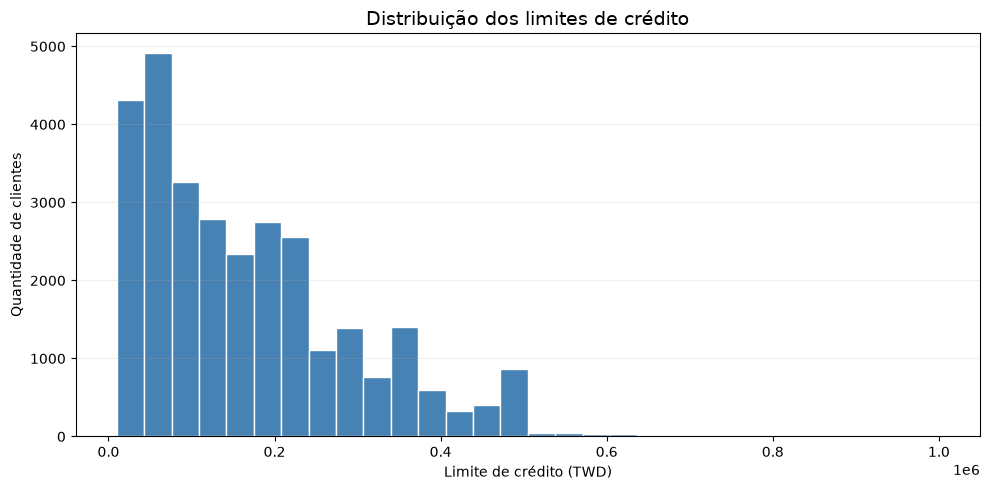

In [ ]:

plt.figure(figsize=(10, 5))

plt.hist(
    df["LIMIT_BAL"],
    bins=30,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribuição dos limites de crédito", fontsize=14)
plt.xlabel("Limite de crédito (TWD)")
plt.ylabel("Quantidade de clientes")

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# Com o histograma, podemos visualizar a distribuição dos limites de crédito dos clientes. 
# Observamos que a maioria dos clientes possui limites de crédito mais baixos, 
# enquanto há alguns clientes com limites muito altos, 
# o que confirma nossa observação anterior sobre a diferença entre o limite médio e o limite mediano.

In [30]:
df["faixa_limite"] = pd.cut(
    df["LIMIT_BAL"],
    bins=[0, 50000, 100000, 200000, 400000, float("inf")],
    labels=["0-50k", "50k-100k", "100k-200k", "200k-400k", "400k+"]
)

df["faixa_limite"].value_counts().sort_index()

faixa_limite
0-50k        7676
50k-100k     4822
100k-200k    7880
200k-400k    7818
400k+        1804
Name: count, dtype: int64

In [31]:
indicadores_limite = df.groupby(
    "faixa_limite", observed=True
)["default payment next month"].agg(
    total_clientes="count",
    total_inadimplentes="sum",
    taxa_inadimplencia="mean"
)

indicadores_limite["taxa_inadimplencia"] = (
    indicadores_limite["taxa_inadimplencia"] * 100
).round(2)

indicadores_limite

,total_clientes,total_inadimplentes,taxa_inadimplencia
faixa_limite,,,
0-50k,7676,2440,31.79
50k-100k,4822,1244,25.80
100k-200k,7880,1535,19.48
200k-400k,7818,1200,15.35
400k+,1804,217,12.03


In [32]:
df["PAY_0"].value_counts().sort_index()

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [ ]:
indicadores_atraso = df.groupby("PAY_0")["default payment next month"].agg(
    total_clientes="count",
    total_inadimplentes="sum",
    taxa_inadimplencia="mean"
)

indicadores_atraso["taxa_inadimplencia"] = (
    indicadores_atraso["taxa_inadimplencia"] * 100
).round(2)

indicadores_atraso

# Criei indicadores de inadimplência por atraso no pagamento,
# agrupando os clientes pela coluna PAY_0, que indica o status do pagamento da fatura do mês anterior.
# O DataFrame indicadores_atraso contém o total de clientes, 
# o total de inadimplentes e a taxa de inadimplência para cada status de pagamento.

,total_clientes,total_inadimplentes,taxa_inadimplencia
PAY_0,,,
-2,2759,365,13.23
-1,5686,954,16.78
0,14737,1888,12.81
1,3688,1252,33.95
2,2667,1844,69.14
3,322,244,75.78
4,76,52,68.42
5,26,13,50.00
6,11,6,54.55


In [34]:
colunas_pagamento = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

for coluna in colunas_pagamento:
    print(f"\n{coluna}")
    print(df[coluna].value_counts().sort_index())


PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int6